```python
# Copyright (c) 2026 Louis Gevers
# SPDX-License-Identifier: BSD-3-Clause
```

# Legged Robots Project - Task 2: Flat Terrain Analysis

In this notebook you will analyse the data produced by `01_flat_terrain.ipynb`:
training logs and evaluation rollouts.
There are no simulations here, so it does not need a GPU and can be restarted at any time.

**Before you start:** check out the metrics functions in `src/lr_project/metrics.py`.
This is the only source file that you will have to edit.
We provided two example implementations, but it is up to you to implement the relevant metrics using rollout data (see 2.0c) for your analyses.
There are two kinds of functions, recognizable by their output shape (`N` number of robots, `T` number of timesteps):
- **per-step signals**, shape `(N, T)`: one value per robot and per time step, e.g. to plot a quantity over time.
- **per-robot metrics**, shape `(N,)`: one value per robot, summarizing its whole rollout.

Thanks to `%autoreload`, edits to `metrics.py` are picked up without restarting the kernel.

**Rules for your analysis**
- Every number and figure must come from a cell in this notebook. 
Never copy numbers by hand.
- The sections below list the **minimum** we expect. 
Add any analysis, figure or metric that helps you answer the questions.
- Label every figure: axes with units, a legend when there are several curves, and a title.
- Write your answers under the **[ANSWER]** cells in markdown.
Remember that short and precise beats long.

In [1]:
%load_ext autoreload
%autoreload 2

import math
import numpy as np
import matplotlib.pyplot as plt

from lr_project.rollout import Rollout
from lr_project import registry, analysis, metrics

## 2.0 Collected data

We provide you with an example of how to load three kinds of data you have generated:
the list of runs, the training logs of a run, and its evaluation rollouts.
Run it as is, then reuse the patterns in your analysis sections.

### 2.0a Selecting runs of interest

`registry.runs` lists runs filtered by experiment and variant (the names used in `train.train`), sorted by creation time. 
`runs[-1]` is the latest run (it's a python list).

In [4]:
runs = registry.runs(
    experiment="flat",
    variant="baseline",
)
registry.show(runs)

| experiment | variant | created |
| --- | --- | --- |
| flat | baseline | 2026-11-11_20-37-55 |

In [5]:
run = runs[-1]
registry.show([run])

| experiment | variant | created |
| --- | --- | --- |
| flat | baseline | 2026-11-11_20-37-55 |

### 2.0b Training data

`analysis.load_training_logs` reads the curves logged during training and returns a dictionary `{curve name: (iterations, values)}`. 
`patterns` are regular expressions over the curve names, e.g. `"Episode_Reward/.*"` for all reward terms.
The curve names match the ones you see in TensorBoard.

In [6]:
train_metrics = analysis.load_training_logs(
    run_dir=run.path,
    patterns=["Train/mean_reward", "Train/mean_episode_length", "Episode_Reward/.*"],
)

print("Loaded training metrics:")
for metric in train_metrics.keys():
    print(f"- {metric!r}")

Loaded training metrics:
- 'Episode_Reward/track_linear_velocity'
- 'Episode_Reward/leg_contact_penalty'
- 'Episode_Reward/feet_air_time'
- 'Episode_Reward/body_linear_velocity_penalty'
- 'Episode_Reward/action_rate'
- 'Episode_Reward/track_angular_velocity'
- 'Episode_Reward/body_angular_velocity_penalty'
- 'Episode_Reward/body_tilt'
- 'Episode_Reward/base_contact_penalty'
- 'Episode_Reward/joint_torques'
- 'Train/mean_reward'
- 'Train/mean_episode_length'


Below we provide an example of plotting training logs, specifically the mean reward per learning iteration:

Loaded 500 iterations of mean reward with last 3 elements: [38.88172531 38.87840271 38.98479462]


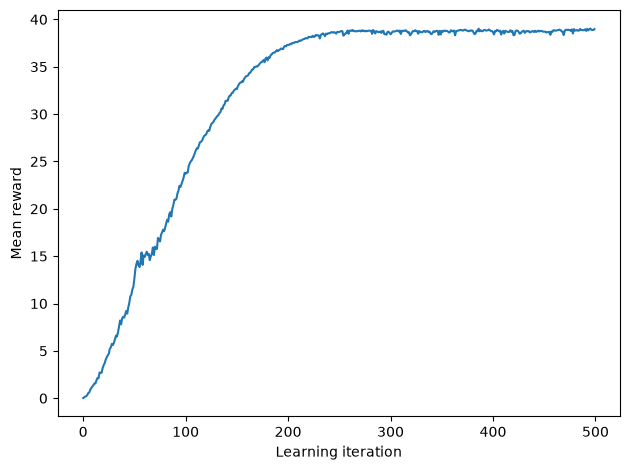

In [7]:
iterations, mean_reward = train_metrics["Train/mean_reward"]
print(f"Loaded {len(iterations)} iterations of mean reward with last 3 elements: {mean_reward[-3:]}")

fig, ax = plt.subplots()

ax.plot(iterations, mean_reward)
ax.set_xlabel("Learning iteration")
ax.set_ylabel("Mean reward")

fig.tight_layout()
plt.show()

### 2.0c Evaluation data

`Rollout.load` reads an evaluation saved in notebook 01. 
A `Rollout` holds numpy arrays for N robots and T time steps (see `src/lr_project/rollout.py` for all fields), for example:

| Field | Shape | Content |
| --- | --- | --- |
| `cmd` | (N, 3) | command of each robot $(v_x, v_y, \omega_z)$ |
| `alive` | (N,) | `True` if the robot never fell |
| `base_lin_vel`, `base_ang_vel` | (N, T, 3) | base velocities in the body frame |
| `base_pos`, `base_quat` | (N, T, 3), (N, T, 4) | base position and orientation in the world frame |
| `joint_pos`, `joint_vel`, `joint_torque` | (N, T, 12) | joint states and torques |
| `foot_contact`, `foot_height` | (N, T, 4) | contact flags and heights of the feet (FL, FR, RL, RR) |
| `foot_grf` | (N, T, 4, 3) | ground reaction forces on the feet |

Robots that fell distort most metrics: compute them on `rollouts.select(rollouts.alive)` and report the survival rate separately.

Below we provide some examples of how to take statistics from rollout data and making a simple figure:

Survival rate is 100.0% (270 out of 270 evaluations alive)
Average linear velocity error is 0.13 (std=0.05)
Robot 69 command: [ 0.5  0.1 -0.1] (lin vel error: 0.08)


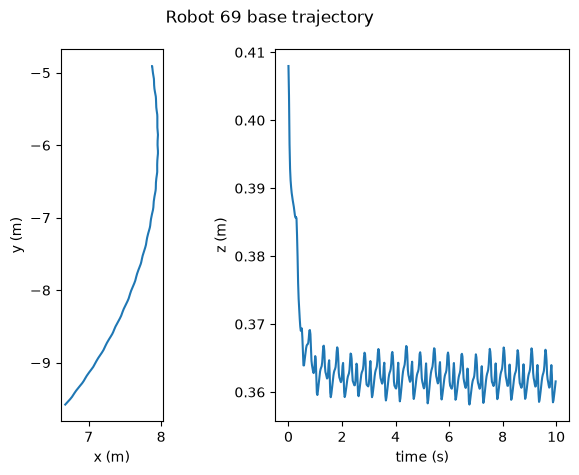

In [16]:
rollouts = Rollout.load(run.eval_file("command_grid"))

n_robot = len(rollouts.alive)
survive_count = np.sum(rollouts.alive)
survival_rate = np.mean(rollouts.alive)

lin_vel_error = metrics.lin_vel_error(rollouts)

print(f"Survival rate is {survival_rate:.1%} ({np.sum(rollouts.alive)} out of {n_robot} evaluations alive)")
print(f"Average linear velocity error is {np.mean(lin_vel_error):.2f} (std={np.std(lin_vel_error):.2f})")

robot_id = 69
print(f"Robot {robot_id} command: {rollouts.cmd[robot_id]} (lin vel error: {lin_vel_error[robot_id]:.2f})")

fig, axes = plt.subplots(nrows=1, ncols=2)

time = rollouts.dt * np.arange(0, rollouts.base_pos.shape[1])
base_x = rollouts.base_pos[robot_id, :, 0]
base_y = rollouts.base_pos[robot_id, :, 1]
base_z = rollouts.base_pos[robot_id, :, 2]

axes[0].plot(base_x, base_y)
axes[0].set_aspect("equal")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")

axes[1].plot(time, base_z)
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("z (m)")

fig.suptitle(f"Robot {robot_id} base trajectory")
fig.tight_layout()
plt.show()

## 2.1 Baseline performance

In this section you will characterize your baseline policy: how it learned, how well it performs, and discuss whether it could run on a real robot.

First load the training and rollout data:

In [13]:
# TODO: Load your baseline training and rollout data here
baseline_run = run
baseline_train_metrics = train_metrics
baseline_rollouts = rollouts

# Use successful trials for walking metrics; report survival separately.
baseline_survivors = baseline_rollouts.select(baseline_rollouts.alive)

### 2.1a Training performance

**Minimum:** mean reward and mean episode length curves, and the curves of the individual reward terms.

Questions: 
- When does the policy converge, and would more training help? 
- Which reward terms dominate, and which improve first? 
- Explain how you arrived at your baseline: which settings you tuned, what failures you observed along the way, and how you fixed them.

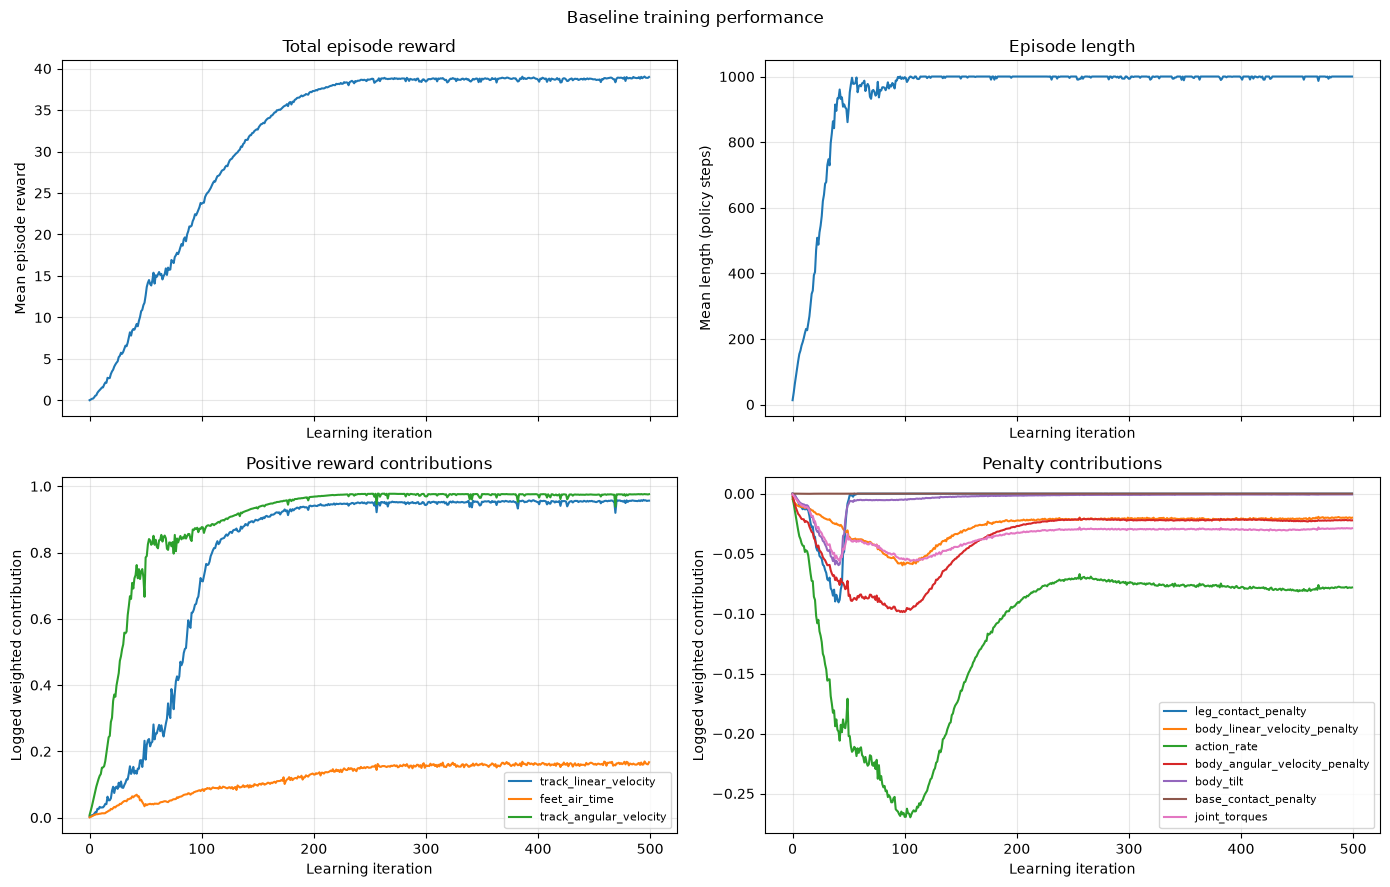

In [14]:
# TODO: create your figures on training performance here
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)

# 1. Is the robot earning a better total score as training progresses?
iterations, values = baseline_train_metrics["Train/mean_reward"]
axes[0, 0].plot(iterations, values)
axes[0, 0].set_title("Total episode reward")
axes[0, 0].set_ylabel("Mean episode reward")

# 2. Is the robot lasting longer before falling or reaching the time limit?
iterations, values = baseline_train_metrics["Train/mean_episode_length"]
axes[0, 1].plot(iterations, values)
axes[0, 1].set_title("Episode length")
axes[0, 1].set_ylabel("Mean length (policy steps)")

# These terms earn points; the remaining terms deduct points.
positive_terms = {
    "track_linear_velocity",
    "track_angular_velocity",
    "feet_air_time",
}

# 3. Look at each scoring rule separately.
for tag, (iterations, values) in baseline_train_metrics.items():
    if not tag.startswith("Episode_Reward/"):
        continue

    term_name = tag.split("/", 1)[1]

    if term_name in positive_terms:
        ax = axes[1, 0]
    else:
        ax = axes[1, 1]

    ax.plot(iterations, values, label=term_name)

axes[1, 0].set_title("Positive reward contributions")
axes[1, 1].set_title("Penalty contributions")

for ax in axes[1]:
    ax.set_ylabel("Logged weighted contribution")
    ax.legend(fontsize=8)

for ax in axes.flat:
    ax.set_xlabel("Learning iteration")
    ax.grid(alpha=0.3)

fig.suptitle("Baseline training performance")
fig.tight_layout()
plt.show()

**[ANSWER]** *Write your answer to the questions here, 2 paragraphs max*

OUT NOTES: 
Total reward — higher is better: rises to about 39, then plateaus around iteration 250, suggesting little further improvement in the training score.

Episode length — higher is better, up to the limit: reaches approximately 1,000 steps by iteration 100. The robots learn to survive full episodes before tracking finishes improving.

Positive rewards — higher means more credit: turning improves first, followed by linear tracking. Both finish high; air time contributes a smaller stepping bonus.

Penalties — closer to zero is better: costs initially increase, then decrease as training progresses. Sudden action changes remain the largest weighted penalty. Early near-zero penalties partly reflect very short episodes, rather than good walking.

### 2.1b Evaluation performance

**Minimum:**
- velocity tracking: linear and yaw rate errors, overall and per command
- cost of transport
- base stability, with a metric of your own design
- foot ground reaction forces
- a foot contact plot (which foot is on the ground over time)

Questions: 
- Which commands are tracked well, and which are hardest? 
- Which gait did the policy learn, and how can you tell from the contact plot? 
- Is the motion efficient and smooth?

Survival: 100.0%
Linear RMS error: 0.127 ± 0.050 m/s
Yaw RMS error: 0.022 ± 0.005 rad/s
Mechanical cost of transport: 0.404 ± 0.029
Steady base-height variation: 2.53 mm
Mean total vertical support: 0.991 body weights
Mean action change: 1.249 (L2 per policy step)
Foot-plot example command: [1. 0. 0.]


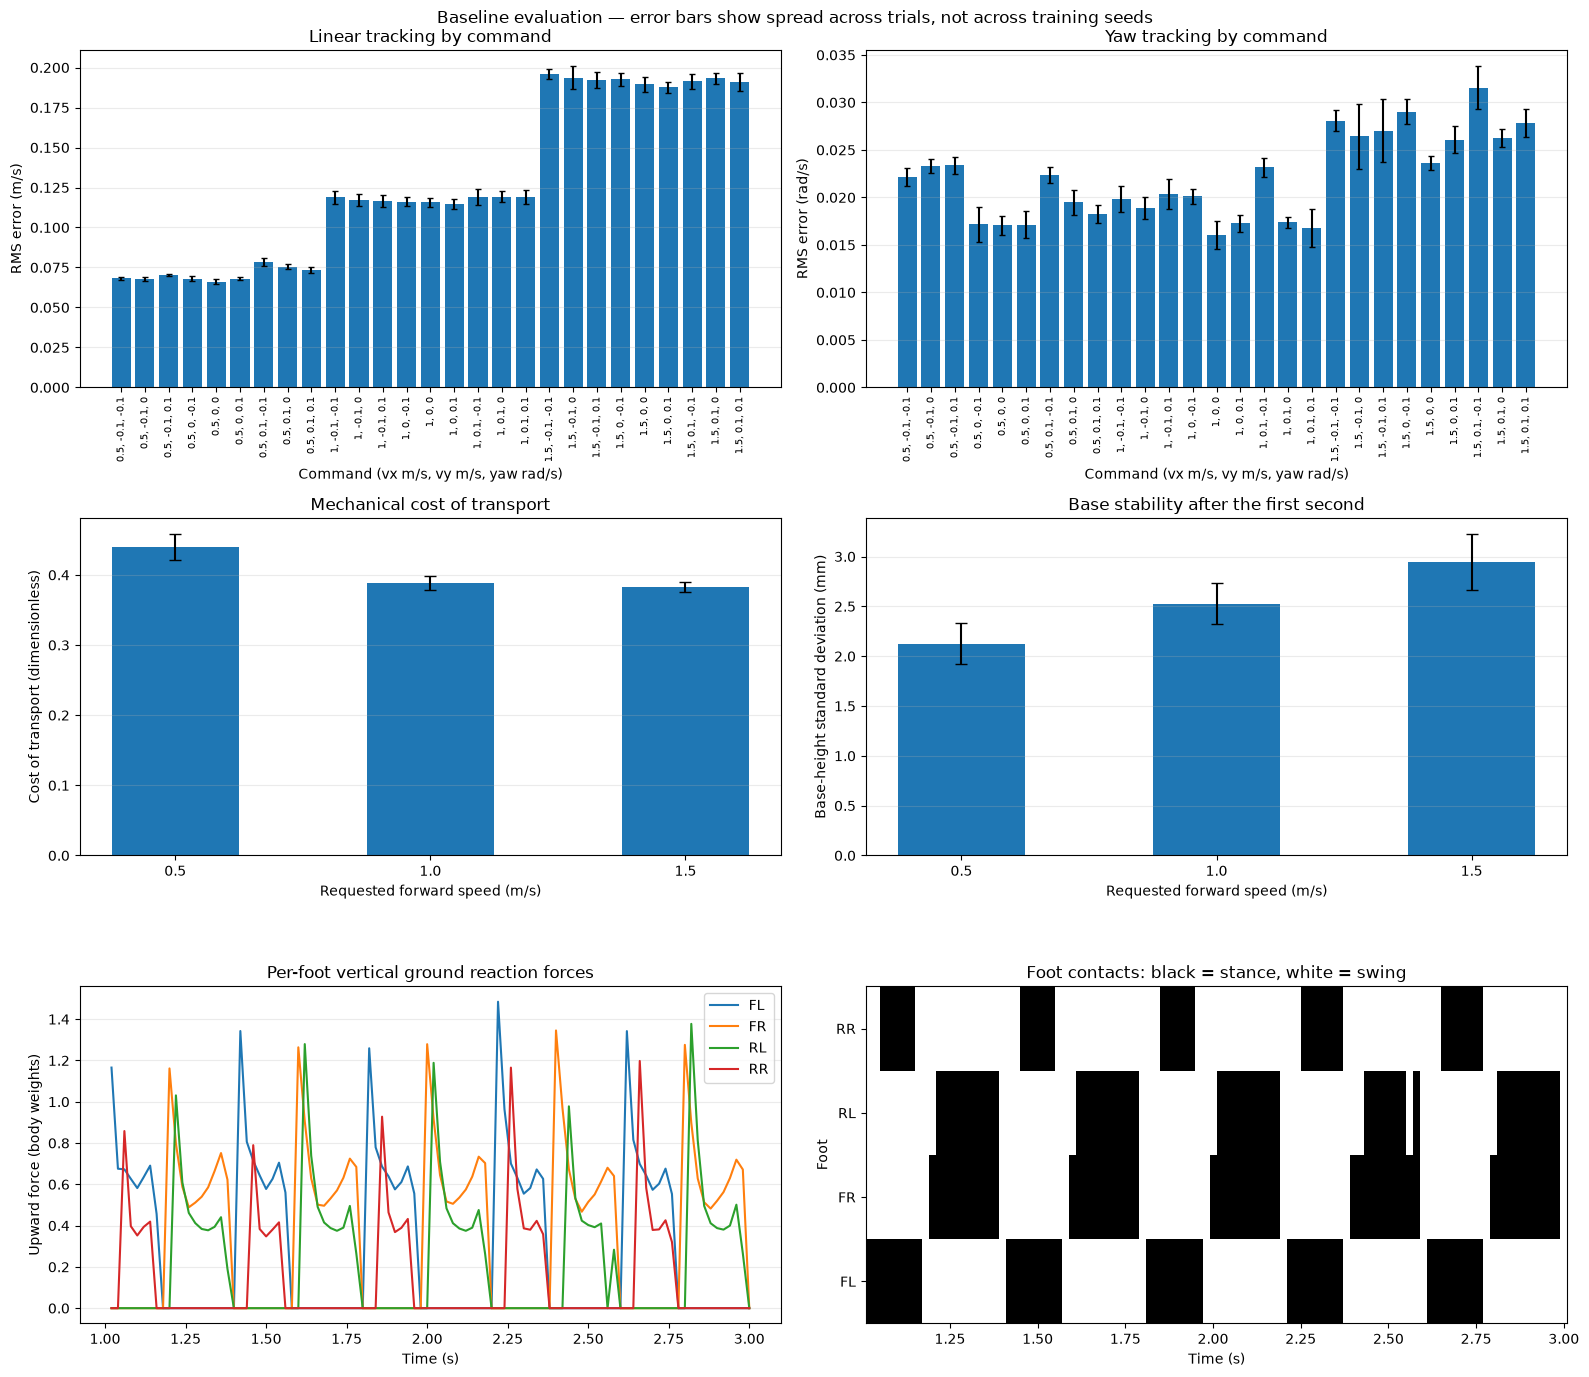

In [17]:
# TODO: create your figures on evaluation performance here
# Use surviving robots for walking metrics; report survival separately.
r = baseline_rollouts.select(baseline_rollouts.alive)

# ------------------------------------------------------------
# Calculate overall performance.
# ------------------------------------------------------------

linear_difference = r.base_lin_vel[..., :2] - r.cmd[:, None, :2]
linear_error = np.sqrt(np.mean(np.sum(linear_difference**2, axis=2), axis=1))

yaw_difference = r.base_ang_vel[..., 2] - r.cmd[:, None, 2]
yaw_error = np.sqrt(np.mean(yaw_difference**2, axis=1))

# Mechanical effort: absolute torque times joint velocity, summed over joints.
power = np.sum(np.abs(r.joint_torque * r.joint_vel), axis=2)
mean_speed = np.mean(np.linalg.norm(r.base_lin_vel[..., :2], axis=2), axis=1)
body_weight = r.mass * 9.81

# Mechanical cost per distance travelled, normalized by body weight.
denominator = body_weight * mean_speed
cot = np.divide(
    power.mean(axis=1),
    denominator,
    out=np.full_like(mean_speed, np.nan),
    where=denominator > 0,
)

# Our stability metric: how much the base height varies after settling.
# Smaller standard deviation means less vertical bouncing.
settling_steps = int(round(1.0 / r.dt))
height_std = np.std(r.base_pos[:, settling_steps:, 2], axis=1)

# Command smoothness: change between consecutive policy actions.
action_change = np.linalg.norm(np.diff(r.action, axis=1), axis=2).mean(axis=1)

# The saved sensor forces are foot-on-ground forces.
# Reverse their sign to obtain the upward ground reaction on the feet.
upward_forces = -r.foot_grf[..., 2]
total_support = upward_forces.sum(axis=2) / body_weight[:, None]

print(f"Survival: {baseline_rollouts.alive.mean():.1%}")
print(f"Linear RMS error: {linear_error.mean():.3f} ± {linear_error.std():.3f} m/s")
print(f"Yaw RMS error: {yaw_error.mean():.3f} ± {yaw_error.std():.3f} rad/s")
print(f"Mechanical cost of transport: {np.nanmean(cot):.3f} ± {np.nanstd(cot):.3f}")
print(f"Steady base-height variation: {1000 * height_std.mean():.2f} mm")
print(f"Mean total vertical support: {total_support.mean():.3f} body weights")
print(f"Mean action change: {action_change.mean():.3f} (L2 per policy step)")

# ------------------------------------------------------------
# Group repeated evaluations of each command.
# ------------------------------------------------------------

commands = np.unique(r.cmd, axis=0)
labels = []
linear_means, linear_stds = [], []
yaw_means, yaw_stds = [], []

for command in commands:
    selected = np.all(np.isclose(r.cmd, command), axis=1)
    labels.append(f"{command[0]:g}, {command[1]:g}, {command[2]:g}")

    linear_means.append(linear_error[selected].mean())
    linear_stds.append(linear_error[selected].std())
    yaw_means.append(yaw_error[selected].mean())
    yaw_stds.append(yaw_error[selected].std())

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
x = np.arange(len(commands))

axes[0, 0].bar(x, linear_means, yerr=linear_stds, capsize=2)
axes[0, 0].set_title("Linear tracking by command")
axes[0, 0].set_ylabel("RMS error (m/s)")

axes[0, 1].bar(x, yaw_means, yerr=yaw_stds, capsize=2)
axes[0, 1].set_title("Yaw tracking by command")
axes[0, 1].set_ylabel("RMS error (rad/s)")

for ax in axes[0]:
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_xlabel("Command (vx m/s, vy m/s, yaw rad/s)")

# ------------------------------------------------------------
# Compare effort and stability at different forward speeds.
# ------------------------------------------------------------

speeds = np.unique(r.cmd[:, 0])
cot_means, cot_stds = [], []
height_means, height_stds = [], []

for speed in speeds:
    selected = np.isclose(r.cmd[:, 0], speed)
    cot_means.append(np.nanmean(cot[selected]))
    cot_stds.append(np.nanstd(cot[selected]))
    height_means.append(1000 * height_std[selected].mean())
    height_stds.append(1000 * height_std[selected].std())

axes[1, 0].bar(speeds, cot_means, yerr=cot_stds, width=0.25, capsize=4)
axes[1, 0].set_title("Mechanical cost of transport")
axes[1, 0].set_ylabel("Cost of transport (dimensionless)")

axes[1, 1].bar(speeds, height_means, yerr=height_stds, width=0.25, capsize=4)
axes[1, 1].set_title("Base stability after the first second")
axes[1, 1].set_ylabel("Base-height standard deviation (mm)")

for ax in axes[1]:
    ax.set_xticks(speeds)
    ax.set_xlabel("Requested forward speed (m/s)")

# ------------------------------------------------------------
# Inspect foot forces and gait for a representative straight walk.
# Choose the first trial closest to command (1 m/s, 0, 0).
# ------------------------------------------------------------

example = int(np.argmin(np.linalg.norm(r.cmd - [1.0, 0.0, 0.0], axis=1)))
print(f"Foot-plot example command: {r.cmd[example]}")

time = (np.arange(r.base_pos.shape[1]) + 1) * r.dt
window = (time > 1.0) & (time <= 3.0)
feet = ["FL", "FR", "RL", "RR"]

forces = upward_forces[example] / body_weight[example]

for foot, name in enumerate(feet):
    axes[2, 0].plot(time[window], forces[window, foot], label=name)

axes[2, 0].set_title("Per-foot vertical ground reaction forces")
axes[2, 0].set_xlabel("Time (s)")
axes[2, 0].set_ylabel("Upward force (body weights)")
axes[2, 0].legend()

axes[2, 1].imshow(
    r.foot_contact[example, window].T,
    origin="lower",
    aspect="auto",
    interpolation="nearest",
    cmap="Greys",
    vmin=0,
    vmax=1,
    extent=(
        time[window][0] - r.dt / 2,
        time[window][-1] + r.dt / 2,
        -0.5,
        3.5,
    ),
)
axes[2, 1].set_yticks(range(4))
axes[2, 1].set_yticklabels(feet)
axes[2, 1].set_xlabel("Time (s)")
axes[2, 1].set_ylabel("Foot")
axes[2, 1].set_title("Foot contacts: black = stance, white = swing")

for ax in axes.flat:
    if ax is not axes[2, 1]:
        ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Baseline evaluation — error bars show spread across trials, "
    "not across training seeds"
)
fig.tight_layout()
plt.show()

**[ANSWER]** *Write your answer to the questions here, 2 paragraphs max*

### 2.1c Discussion: deployability

Given your previous observations, would your policy work on the real Go2? 
Discuss:
- **Observations:** can each observation be obtained on the real robot, and how noisy would it be?
- **Actions:** are the commanded motions realistic for the motors (look at torques, joint velocities and action smoothness)?
- **Evaluation on hardware:** which of your metrics could you measure on the real robot, and how?
- **Sim-to-real:** which reward terms or settings did you add to make the policy more transferable, and what is still missing?


**[ANSWER]** *Write your discussion here, 3 paragraphs max*

## 2.2 Controlled experiment

In this section you will describe and report the results of your controlled experiment in section 1.5 of notebook 01 like a short scientific study.

### 2.2a Questions and hypotheses

State your research question and your hypotheses:
- **Null hypothesis $H_0$:** the change has no effect on the metrics you chose.
- **Alternative hypothesis $H_1$:** the change affects the metrics, in a direction you predict, and why.

Name the metrics that will enable to reject the null hypothesis in favor of your alternative hypothesis, answering your research question.

**[ANSWER]** *Write your question, hypotheses, and metrics here.*

### 2.2b Methods

Describe exactly what differs between your baseline and your variant, what was held fixed (training budget, evaluation commands, seeds), how many runs each configuration has, and how you decide whether a difference is real (e.g. larger than the spread between seeds). 
Mention possible confounders.

**[ANSWER]** *Write your methods here. 2 paragraphs max.*

### 2.2c Experimental results

**Minimum:** at least 3 figures comparing baseline and variant, using training curves and/or evaluation metrics. 
Show both configurations in the same figure where possible, with the same axes.

In [ ]:
# TODO: Load your variant training and rollout data here

In [ ]:
# TODO: create your figures here

**[ANSWER]** *Describe what each figure shows here. 2 paragraphs max.*

### 2.2e Discussion

What did you expect, and what did you not expect? 
Do the results support $H_1$ and reject $H_0$, and how conclusive are they (number of runs, size of the difference compared to the variation between runs)? 
Explain the mechanism: how does your change lead to the effect you measured? 
What would you test next?

**[ANSWER]** *Describe your interpretations here. Linking your observations back to the course or the literature is encouraged! 3 paragraphs max.*